# Generative Stress Scenarios (VAE / Conditional GAN)

Stress testing needs coherent joint moves: if equities fall 15% in a month, how far do credit spreads widen, and what do yields and the dollar do? Regulators publish a handful of hand-written paths, and history never repeats exactly. Generative models promise thousands of plausible scenarios, including ones built around a chosen narrative. This notebook checks whether they deliver on a small, honest sample.

**What it does.** It learns the joint monthly distribution of eight U.S. market risk factors (equities, small caps, VIX, 2y and 10y Treasury yields, the Baa credit spread, the dollar and oil).

It generates scenarios with a VAE, a VIX-conditional VAE and an equity-conditional Wasserstein GAN, and scores them against historical simulation and Gaussian and Student-t models on 2017–2026 out of sample.

It then builds reverse stress scenarios ("given equities fall 15%, what else moves?") and their P&L on a treasury-style portfolio.

**Data.** Month-end S&P 500, Russell 2000 and dollar index (Yahoo Finance), 2y and 10y Treasury yields, the Moody's Baa–10y spread, VIX and WTI oil (FRED) from January 1990, and the Federal Reserve's 2026 supervisory scenarios (federalreserve.gov).

**Methods.** Historical bootstrap, multivariate Gaussian and Student-t, a VAE and a conditional VAE (PyTorch), and a conditional WGAN-GP.

They are scored with the energy distance and energy score (proper scoring rules), tail-quantile and tail-dependence checks and VaR exceedance tests, with linear-Gaussian and nearest-neighbour analogues as conditional benchmarks.

**Key output.** An out-of-sample scorecard by generator, how well each model captures tails and stress correlations, reverse-stress factor distributions at −8%, −15% and −20% equity moves, the Fed's 2026 severely adverse scenario against the generators, and the portfolio P&L under each.

## 1. Why generate scenarios

Stress testing needs **coherent joint moves**: if equities fall 15% in a month, how far do credit spreads widen, what do Treasury yields do, and does the dollar rally? Regulators publish a few hand-written paths (the Fed's supervisory scenarios), and risk teams add historical replays such as 2008 or March 2020. Both are thin: a handful of paths, and history does not repeat exactly.

A generative model learns the joint distribution and can produce **thousands of plausible scenarios**, including ones conditioned on a narrative. The validation questions are the same as for any risk model:

1. Out of sample, are the generated scenarios closer to what actually happened than simple alternatives (bootstrap, Gaussian)?
2. Are the **tails** and the **stress correlations** right? Correlations go to one in a crisis, and a Gaussian with full-sample correlations understates that.
3. When conditioned on an extreme equity move, are the other factors' responses plausible and consistent with real episodes?

The sample is small: 37 years of monthly data, about 430 observations, of which only 324 are used for training. That is the honest setting for this problem, and it is why the comparison with simple models matters.

The reverse-stress section conditions on equity shocks of the size of October 2008 and March 2020, and Section 7 runs the Fed's 2026 severely adverse scenario through the same models.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import yfinance as yf
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

TICKERS = ["^GSPC", "^RUT", "DX-Y.NYB"]
FRED_SERIES = {
    "DGS2": "2y yield",
    "DGS10": "10y yield",
    "BAA10Y": "Baa spread",
    "VIXCLS": "VIX",
    "DCOILWTICO": "WTI",
}
START = "1989-11-01"
TRAIN_END = "2016-12-31"  # test = 2017-01 onwards
N_SCEN = 20_000  # scenarios per generator
STRESS_LEVELS = [-0.08, -0.15, -0.20]
SEED = 5
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(
    f"torch {torch.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

torch 2.14.1+cu130 · yfinance 1.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


GEN_COLORS = {
    "Historical bootstrap": "#9c9b97",
    "Gaussian": PALETTE[0],
    "Student-t": PALETTE[3],
    "VAE": PALETTE[2],
    "Conditional VAE (VIX)": PALETTE[6],
    "Conditional WGAN": PALETTE[1],
}

## 3. Data: eight monthly risk factors

In [3]:
def fetch_prices():
    px = yf.download(TICKERS, start=START, auto_adjust=True, progress=False)[
        "Close"
    ]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name, px.columns.name = "date", None
    return px[TICKERS].reset_index()


# Index levels only; month-end values are used, so no daily bad-print cleaning
# is needed
prices = cached("yahoo_prices", fetch_prices).set_index("date").sort_index()
prices = prices[prices.index < pd.Timestamp.today().normalize()].ffill(limit=3)
print(
    f"{len(prices):,} trading days · {prices.index.min():%Y-%m-%d} →"
    f" {prices.index.max():%Y-%m-%d} · {', '.join(prices.columns)}"
)

9,420 trading days · 1989-11-01 → 2026-10-16 · ^GSPC, ^RUT, DX-Y.NYB


In [4]:
def fetch_fred():
    return (
        pd.DataFrame({
            k: fred.get_series(k, observation_start=START) for k in FRED_SERIES
        })
        .rename_axis("date")
        .reset_index()
    )


fr = cached("fred_factors", fetch_fred).set_index("date")
fr.index = pd.to_datetime(fr.index)
levels = pd.concat(
    [prices.resample("ME").last(), fr.resample("ME").last()], axis=1
).dropna()
# complete months only
levels = levels[levels.index < pd.Timestamp.today().normalize().replace(day=1)]

# Monthly factor changes: log returns for prices, changes for yields, spreads
# (bp) and the VIX (points)
X = pd.DataFrame({
    "S&P 500 %": np.log(levels["^GSPC"]).diff() * 100,
    "Russell 2000 %": np.log(levels["^RUT"]).diff() * 100,
    "VIX pts": levels["VIXCLS"].diff(),
    "2y yield bp": levels["DGS2"].diff() * 100,
    "10y yield bp": levels["DGS10"].diff() * 100,
    "Baa spread bp": levels["BAA10Y"].diff() * 100,
    "Dollar %": np.log(levels["DX-Y.NYB"]).diff() * 100,
    "WTI %": np.log(levels["DCOILWTICO"].clip(lower=5)).diff() * 100,
}).dropna()
# VIX at the start of each month (known in advance)
state = np.log(levels["VIXCLS"]).shift(1).reindex(X.index)
FACTORS = list(X.columns)
train, test = X.index <= TRAIN_END, X.index > TRAIN_END
print(
    f"{len(X)} months {X.index.min():%Y-%m} → {X.index.max():%Y-%m} · train"
    f" {train.sum()} · test {test.sum()}"
)
X.describe().T[["mean", "std", "min", "max"]].join(
    X.skew().rename("skew")
).join(X.kurt().rename("excess kurtosis")).round(2)

440 months 1990-02 → 2026-09 · train 323 · test 117


,mean,std,min,max,skew,excess kurtosis
S&P 500 %,0.72,4.26,-18.56,11.94,-0.71,1.46
Russell 2000 %,0.66,5.66,-24.72,16.79,-0.70,1.73
VIX pts,-0.02,4.60,-19.39,21.27,0.50,4.41
2y yield bp,-0.77,25.75,-90.00,84.00,-0.07,1.04
10y yield bp,-0.71,26.07,-108.00,95.00,0.03,0.77
Baa spread bp,-0.05,20.16,-79.00,155.00,1.84,16.24
Dollar %,0.02,2.26,-6.21,9.02,0.25,0.77
WTI %,0.33,10.67,-78.20,61.50,-0.49,9.35


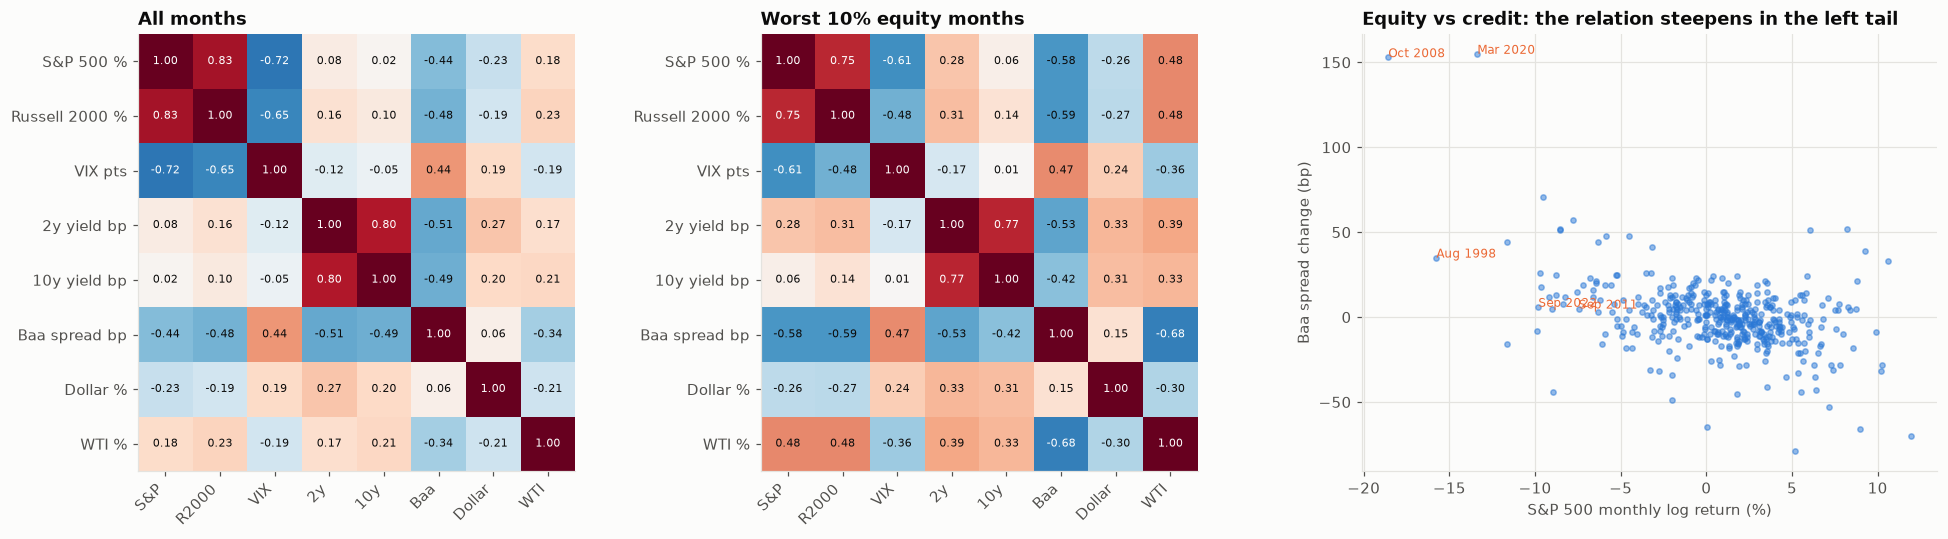

In [5]:
# --- Chart 1: correlations in calm vs stressed months
stressed = X["S&P 500 %"] <= X["S&P 500 %"].quantile(0.10)
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1, 1.2]}
)
for ax, (title, mask) in zip(
    axes[:2],
    [("All months", slice(None)), ("Worst 10% equity months", stressed)],
):
    C = X[mask].corr()
    im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(
        range(len(FACTORS)),
        [
            f.split(" ")[0] if f != "Russell 2000 %" else "R2000"
            for f in FACTORS
        ],
        rotation=45,
        ha="right",
    )
    ax.set_yticks(range(len(FACTORS)), FACTORS)
    for i in range(len(FACTORS)):
        for j in range(len(FACTORS)):
            ax.text(
                j,
                i,
                f"{C.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if abs(C.iloc[i, j]) > 0.6 else INK,
            )
    ax.set_title(title)
    ax.grid(False)
ax = axes[2]
ax.scatter(
    X["S&P 500 %"], X["Baa spread bp"], s=12, alpha=0.5, color=PALETTE[0]
)
for d in [
    "2008-10-31",
    "2020-03-31",
    "2022-09-30",
    "1998-08-31",
    "2011-09-30",
]:
    d = pd.Timestamp(d)
    if d in X.index:
        ax.annotate(
            f"{d:%b %Y}",
            (X.loc[d, "S&P 500 %"], X.loc[d, "Baa spread bp"]),
            fontsize=8,
            color=PALETTE[1],
        )
ax.set_xlabel("S&P 500 monthly log return (%)")
ax.set_ylabel("Baa spread change (bp)")
ax.set_title("Equity vs credit: the relation steepens in the left tail")
plt.tight_layout()
save_fig(fig, "01_correlations_calm_vs_stress")
plt.show()

## 4. The generators

All models are fitted on 1990–2016 only, on standardised factors.

| Generator | Idea |
|---|---|
| **Historical bootstrap** | resample training months: exact empirical joint distribution, but nothing new |
| **Gaussian** | sample mean and covariance |
| **Student-t** | multivariate $t$, degrees of freedom by maximum likelihood: fat tails, but one tail-dependence parameter for everything |
| **VAE** | encoder → 3-dimensional latent → decoder; sampling the latent prior gives new scenarios (Kingma & Welling, 2014) |
| **Conditional VAE (VIX)** | the VAE with the starting VIX level as an input, so scenarios depend on the market state |
| **Conditional WGAN** | generator of the seven other factors **given the equity return**, trained adversarially with a Wasserstein loss and gradient penalty (Gulrajani et al., 2017) |

In [6]:
mu_tr, sd_tr = X[train].mean(), X[train].std()
Z = ((X - mu_tr) / sd_tr).to_numpy(dtype=np.float32)
Ztr, Zte = Z[train], Z[test]
s_mu, s_sd = state[train].mean(), state[train].std()
S = ((state - s_mu) / s_sd).to_numpy(dtype=np.float32)
Str, Ste = S[train], S[test]
rng = np.random.default_rng(SEED)
D = len(FACTORS)


def to_units(z):
    return z * sd_tr.to_numpy() + mu_tr.to_numpy()


# --- Classical generators
def gen_bootstrap(n):
    return Ztr[rng.integers(0, len(Ztr), n)]


cov_tr = np.cov(Ztr.T)


def gen_gaussian(n):
    return rng.multivariate_normal(np.zeros(D), cov_tr, n)


def t_loglik(nu):
    Sig = cov_tr * (nu - 2) / nu
    return (
        stats.multivariate_t(loc=np.zeros(D), shape=Sig, df=nu)
        .logpdf(Ztr)
        .sum()
    )


NU = max(np.arange(3, 31, 0.5), key=t_loglik)


def gen_student_t(n):
    return stats.multivariate_t(
        loc=np.zeros(D), shape=cov_tr * (NU - 2) / NU, df=NU
    ).rvs(n, random_state=rng)


print(f"Student-t degrees of freedom (ML): {NU:.1f}")

Student-t degrees of freedom (ML): 6.5


In [7]:
class VAE(torch.nn.Module):
    def __init__(self, d, c=0, latent=3, h=64):
        super().__init__()
        self.c, self.latent = c, latent
        self.enc = torch.nn.Sequential(
            torch.nn.Linear(d + c, h),
            torch.nn.SiLU(),
            torch.nn.Linear(h, h),
            torch.nn.SiLU(),
            torch.nn.Linear(h, 2 * latent),
        )
        self.dec = torch.nn.Sequential(
            torch.nn.Linear(latent + c, h),
            torch.nn.SiLU(),
            torch.nn.Linear(h, h),
            torch.nn.SiLU(),
            torch.nn.Linear(h, d),
        )
        # decoder noise per factor
        self.log_sigma = torch.nn.Parameter(torch.full((d,), -1.0))

    def forward(self, x, cond=None):
        inp = x if cond is None else torch.cat([x, cond], 1)
        mu, logvar = self.enc(inp).chunk(2, 1)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        out = self.dec(z if cond is None else torch.cat([z, cond], 1))
        return out, mu, logvar

    def sample(self, n, cond=None):
        with torch.no_grad():
            z = torch.randn(n, self.latent)
            mean = self.dec(z if cond is None else torch.cat([z, cond], 1))
            return (
                mean + torch.randn_like(mean) * torch.exp(self.log_sigma)
            ).numpy()


def train_vae(model, x, cond=None, epochs=4_000, lr=2e-3, beta=1.0):
    x = torch.tensor(x)
    cond = None if cond is None else torch.tensor(cond).reshape(-1, 1)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    for ep in range(epochs):
        out, mu, logvar = model(x, cond)
        nll = (
            (
                0.5 * ((x - out) / torch.exp(model.log_sigma)) ** 2
                + model.log_sigma
            )
            .sum(1)
            .mean()
        )
        kl = -0.5 * (1 + logvar - mu**2 - logvar.exp()).sum(1).mean()
        loss = nll + beta * kl
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model, nll.item(), kl.item()


t0 = time.perf_counter()
vae, nll, kl = train_vae(VAE(D), Ztr)
cvae, nll_c, kl_c = train_vae(VAE(D, c=1), Ztr, Str)
print(
    f"VAE: recon NLL {nll:.2f}, KL {kl:.2f} · CVAE: recon NLL {nll_c:.2f}, KL"
    f" {kl_c:.2f} · {time.perf_counter() - t0:.0f}s"
)


def gen_vae(n):
    return vae.sample(n)


def gen_cvae(n, s=None):
    """Unconditional use: draw starting states from the training history."""
    s = (
        Str[rng.integers(0, len(Str), n)]
        if s is None
        else np.full(n, s, dtype=np.float32)
    )
    return cvae.sample(n, torch.tensor(s).reshape(-1, 1))

VAE: recon NLL -3.60, KL 4.21 · CVAE: recon NLL -6.11, KL 5.42 · 19s


In [8]:
EQ = FACTORS.index("S&P 500 %")
OTHERS = [i for i in range(D) if i != EQ]


class Generator(torch.nn.Module):
    def __init__(self, nz=8, h=96):
        super().__init__()
        self.nz = nz
        self.net = torch.nn.Sequential(
            torch.nn.Linear(nz + 1, h),
            torch.nn.SiLU(),
            torch.nn.Linear(h, h),
            torch.nn.SiLU(),
            torch.nn.Linear(h, D - 1),
        )

    def forward(self, c):
        return self.net(torch.cat([torch.randn(len(c), self.nz), c], 1))


class Critic(torch.nn.Module):
    def __init__(self, h=96):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(D, h),
            torch.nn.SiLU(),
            torch.nn.Linear(h, h),
            torch.nn.SiLU(),
            torch.nn.Linear(h, 1),
        )

    def forward(self, y, c):
        return self.net(torch.cat([y, c], 1))


def train_cwgan(x, iters=6_000, n_critic=5, gp=10.0, batch=128, seed=SEED):
    torch.manual_seed(seed)
    x = torch.tensor(x)
    c_all, y_all = x[:, [EQ]], x[:, OTHERS]
    G, C = Generator(), Critic()
    og = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.9))
    oc = torch.optim.Adam(C.parameters(), lr=1e-4, betas=(0.5, 0.9))
    hist = []
    for it in range(iters):
        for _ in range(n_critic):
            b = torch.randint(0, len(x), (batch,))
            c, y = c_all[b], y_all[b]
            fake = G(c).detach()
            eps = torch.rand(batch, 1)
            mix = (eps * y + (1 - eps) * fake).requires_grad_(True)
            grad = torch.autograd.grad(
                C(mix, c).sum(), mix, create_graph=True
            )[0]
            loss_c = (
                C(fake, c).mean()
                - C(y, c).mean()
                + gp * ((grad.norm(dim=1) - 1) ** 2).mean()
            )
            oc.zero_grad()
            loss_c.backward()
            oc.step()
        b = torch.randint(0, len(x), (batch,))
        loss_g = -C(G(c_all[b]), c_all[b]).mean()
        og.zero_grad()
        loss_g.backward()
        og.step()
        if it % 200 == 0:
            hist.append(-loss_c.item())
    return G, hist


t0 = time.perf_counter()
G, w_hist = train_cwgan(Ztr)
print(
    "Conditional WGAN-GP: 6,000 generator steps in"
    f" {time.perf_counter() - t0:.0f}s · final Wasserstein estimate"
    f" {w_hist[-1]:.3f}"
)


def gen_cwgan_given(c):
    """Seven other factors given standardised equity returns c (array)."""
    with torch.no_grad():
        y = G(
            torch.tensor(np.asarray(c, dtype=np.float32)).reshape(-1, 1)
        ).numpy()
    out = np.empty((len(y), D), dtype=np.float32)
    out[:, EQ], out[:, OTHERS] = np.asarray(c).ravel(), y
    return out


def gen_cwgan(n):
    """
    Unconditional use: draw equity returns from the training history, then the
    rest from the generator.
    """
    return gen_cwgan_given(Ztr[rng.integers(0, len(Ztr), n), EQ])

Conditional WGAN-GP: 6,000 generator steps in 90s · final Wasserstein estimate 0.193


## 5. Out-of-sample scorecard, 2017–2026

Each generator produces 20,000 scenarios, which are compared with the 115-odd test months:

- **Energy distance** between the generated and the realised test distribution, a proper two-sample metric for multivariate distributions (lower is better).
- **Correlation error:** Frobenius distance between scenario and test correlation matrices, for all months and for the worst-decile equity months.
- **Tail error:** mean absolute error of the 5% and 95% quantiles across factors, in standard deviations.
- **Tail dependence:** the probability that the Baa spread is in its top 10% when equities are in their bottom 10%; the empirical value over the full sample is the reference.
- **Portfolio VaR exceedances:** the 95% one-month VaR of a stylised treasury portfolio (below) from each generator's scenarios, and how many test months breach it (expected 5%, with a Kupiec test).

The test period contains March 2020, the 2022 rate shock and the 2023 regional-bank stress, none of which are in training.

In [9]:
def energy_distance(A, B, n=1_500):
    A = A[rng.integers(0, len(A), min(n, len(A)))]

    def mean_dist(P, Q):
        return np.mean(np.linalg.norm(P[:, None, :] - Q[None, :, :], axis=2))

    return 2 * mean_dist(A, B) - mean_dist(A, A) - mean_dist(B, B)


# Stylised MDB treasury portfolio, P&L in $mm per unit factor move (linear
# sensitivities)
EXPOSURE = {
    "S&P 500 %": 2.0,  # $200mm equity sleeve: $2mm per 1%
    "Russell 2000 %": 0.0,
    "VIX pts": -0.3,  # short-vol overlay / option book
    "2y yield bp": -0.20,  # $1bn short Treasuries, DV01 $0.2mm
    "10y yield bp": -0.45,  # $600mm 7–10y bonds, DV01 $0.45mm
    "Baa spread bp": -0.55,  # $700mm IG credit, CS01 $0.55mm
    "Dollar %": -1.5,  # unhedged non-USD bonds
    "WTI %": 0.2,
}
w_pnl = np.array([EXPOSURE[f] for f in FACTORS])


def pnl(Zs):
    return to_units(Zs) @ w_pnl


test_units = X[test].to_numpy()
pnl_test = test_units @ w_pnl
TD_REF = (
    (X["Baa spread bp"] >= X["Baa spread bp"].quantile(0.9))
    & (X["S&P 500 %"] <= X["S&P 500 %"].quantile(0.1))
).mean() / 0.1
stress_te = X.loc[test, "S&P 500 %"] <= X["S&P 500 %"].quantile(0.10)

GENERATORS = {
    "Historical bootstrap": gen_bootstrap,
    "Gaussian": gen_gaussian,
    "Student-t": gen_student_t,
    "VAE": gen_vae,
    "Conditional VAE (VIX)": gen_cvae,
    "Conditional WGAN": gen_cwgan,
}
scen, rows = {}, {}
for name, g in GENERATORS.items():
    Zs = np.asarray(g(N_SCEN), dtype=np.float64)
    scen[name] = Zs
    U = to_units(Zs)
    Us = pd.DataFrame(U, columns=FACTORS)
    q_err = np.mean([
        np.abs(np.quantile(Zs[:, j], q) - np.quantile(Zte[:, j], q))
        for j in range(D)
        for q in (0.05, 0.95)
    ])
    s_mask = Us["S&P 500 %"] <= np.quantile(Us["S&P 500 %"], 0.10)
    td = (
        (Us["Baa spread bp"] >= Us["Baa spread bp"].quantile(0.9))
        & (Us["S&P 500 %"] <= Us["S&P 500 %"].quantile(0.1))
    ).mean() / 0.1
    var95 = -np.quantile(pnl(Zs), 0.05)
    exc = int((pnl_test < -var95).sum())
    n = len(pnl_test)
    p_hat = max(exc / n, 1e-9)
    lr = -2 * (
        (n - exc) * np.log(0.95)
        + exc * np.log(0.05)
        - (n - exc) * np.log(1 - p_hat)
        - (exc * np.log(p_hat) if exc else 0)
    )
    rows[name] = {
        "energy distance": energy_distance(Zs, Zte),
        "corr error (all)": np.linalg.norm(
            Us.corr().to_numpy() - X[test].corr().to_numpy()
        ),
        "corr error (stress)": np.linalg.norm(
            Us[s_mask].corr().to_numpy() - X[test][stress_te].corr().to_numpy()
        ),
        "tail quantile error (sd)": q_err,
        "tail dependence eq↓/credit↑": td,
        "95% VaR $mm": var95,
        "test exceedances": exc,
        "Kupiec p": 1 - stats.chi2.cdf(lr, 1),
    }
scorecard = pd.DataFrame(rows).T
print(
    f"Reference tail dependence (full sample): {TD_REF:.2f} · test months:"
    f" {len(pnl_test)}, expected exceedances {0.05 * len(pnl_test):.1f}"
)
scorecard.round(3)

Reference tail dependence (full sample): 0.45 · test months: 117, expected exceedances 5.9


,energy distance,corr error (all),corr error (stress),tail quantile error (sd),tail dependence eq↓/credit↑,95% VaR $mm,test exceedances,Kupiec p
Historical bootstrap,0.06,1.49,2.37,0.33,0.46,27.15,16.00,0.00
Gaussian,0.07,1.48,2.89,0.31,0.26,29.29,14.00,0.00
Student-t,0.05,1.46,2.84,0.33,0.30,28.40,15.00,0.00
VAE,0.07,1.75,2.46,0.34,0.33,27.60,16.00,0.00
Conditional VAE (VIX),0.07,1.79,2.60,0.38,0.39,23.95,18.00,0.00
Conditional WGAN,0.07,1.93,2.21,0.36,0.44,23.78,18.00,0.00


### Conditional skill: energy score month by month

The scorecard above treats the test period as one distribution. A **conditional** model should do better month by month, because it knows something about each month in advance. The energy score $\mathrm{ES}(F, y) = \mathbb{E}\lVert Y - y\rVert - \tfrac12\mathbb{E}\lVert Y - Y'\rVert$ is a proper scoring rule for a multivariate forecast $F$ and the realised vector $y$; it is averaged over test months (lower is better).

- **State-conditional:** the CVAE gets the VIX at the start of the month. Its benchmark is the bootstrap restricted to training months with a similar starting VIX (the 40 nearest).
- **Equity-conditional:** given the month's actual S&P 500 return, how well is the joint move of the other seven factors predicted? The WGAN is compared with the linear-Gaussian conditional distribution and with the 40 nearest historical analogues.

In [10]:
def energy_score(samples, y):
    a = np.mean(np.linalg.norm(samples - y, axis=1))
    half = len(samples) // 2
    b = np.mean(
        np.linalg.norm(samples[:half] - samples[half : 2 * half], axis=1)
    )
    return a - 0.5 * b


M = 2_000
# Gaussian conditional of the other factors given equity
S11 = cov_tr[np.ix_(OTHERS, OTHERS)]
S12 = cov_tr[np.ix_(OTHERS, [EQ])]
beta = (S12 / cov_tr[EQ, EQ]).ravel()
S_cond = S11 - np.outer(S12, S12) / cov_tr[EQ, EQ]

es = {
    k: []
    for k in [
        "Unconditional bootstrap",
        "VIX-analogue bootstrap",
        "Conditional VAE (VIX)",
        "Linear-Gaussian | equity",
        "Historical analogues | equity",
        "Conditional WGAN | equity",
    ]
}
for k, y in enumerate(Zte):
    s0, c0 = Ste[k], y[EQ]
    es["Unconditional bootstrap"].append(energy_score(gen_bootstrap(M), y))
    near = np.argsort(np.abs(Str - s0))[:40]
    es["VIX-analogue bootstrap"].append(
        energy_score(Ztr[near][rng.integers(0, 40, M)], y)
    )
    es["Conditional VAE (VIX)"].append(energy_score(gen_cvae(M, s0), y))
    yo = y[OTHERS]
    g_lin = rng.multivariate_normal(beta * c0, S_cond, M)
    es["Linear-Gaussian | equity"].append(energy_score(g_lin, yo))
    near_e = np.argsort(np.abs(Ztr[:, EQ] - c0))[:40]
    es["Historical analogues | equity"].append(
        energy_score(Ztr[near_e][:, OTHERS][rng.integers(0, 40, M)], yo)
    )
    es["Conditional WGAN | equity"].append(
        energy_score(gen_cwgan_given(np.full(M, c0))[:, OTHERS], yo)
    )
es = pd.DataFrame(es, index=X.index[test])
stress_rows = es.index[stress_te.to_numpy()]
cond_table = pd.DataFrame({
    "mean energy score (all test months)": es.mean(),
    "mean energy score (worst-decile equity months)": es.loc[
        stress_rows
    ].mean(),
})
cond_table["group"] = ["state", "state", "state", "equity", "equity", "equity"]
cond_table.round(3)

,mean energy score (all test months),mean energy score (worst-decile equity months),group
Unconditional bootstrap,1.92,3.92,state
VIX-analogue bootstrap,1.90,3.91,state
Conditional VAE (VIX),1.88,3.91,state
Linear-Gaussian | equity,1.56,2.74,equity
Historical analogues | equity,1.61,2.84,equity
Conditional WGAN | equity,1.62,2.88,equity


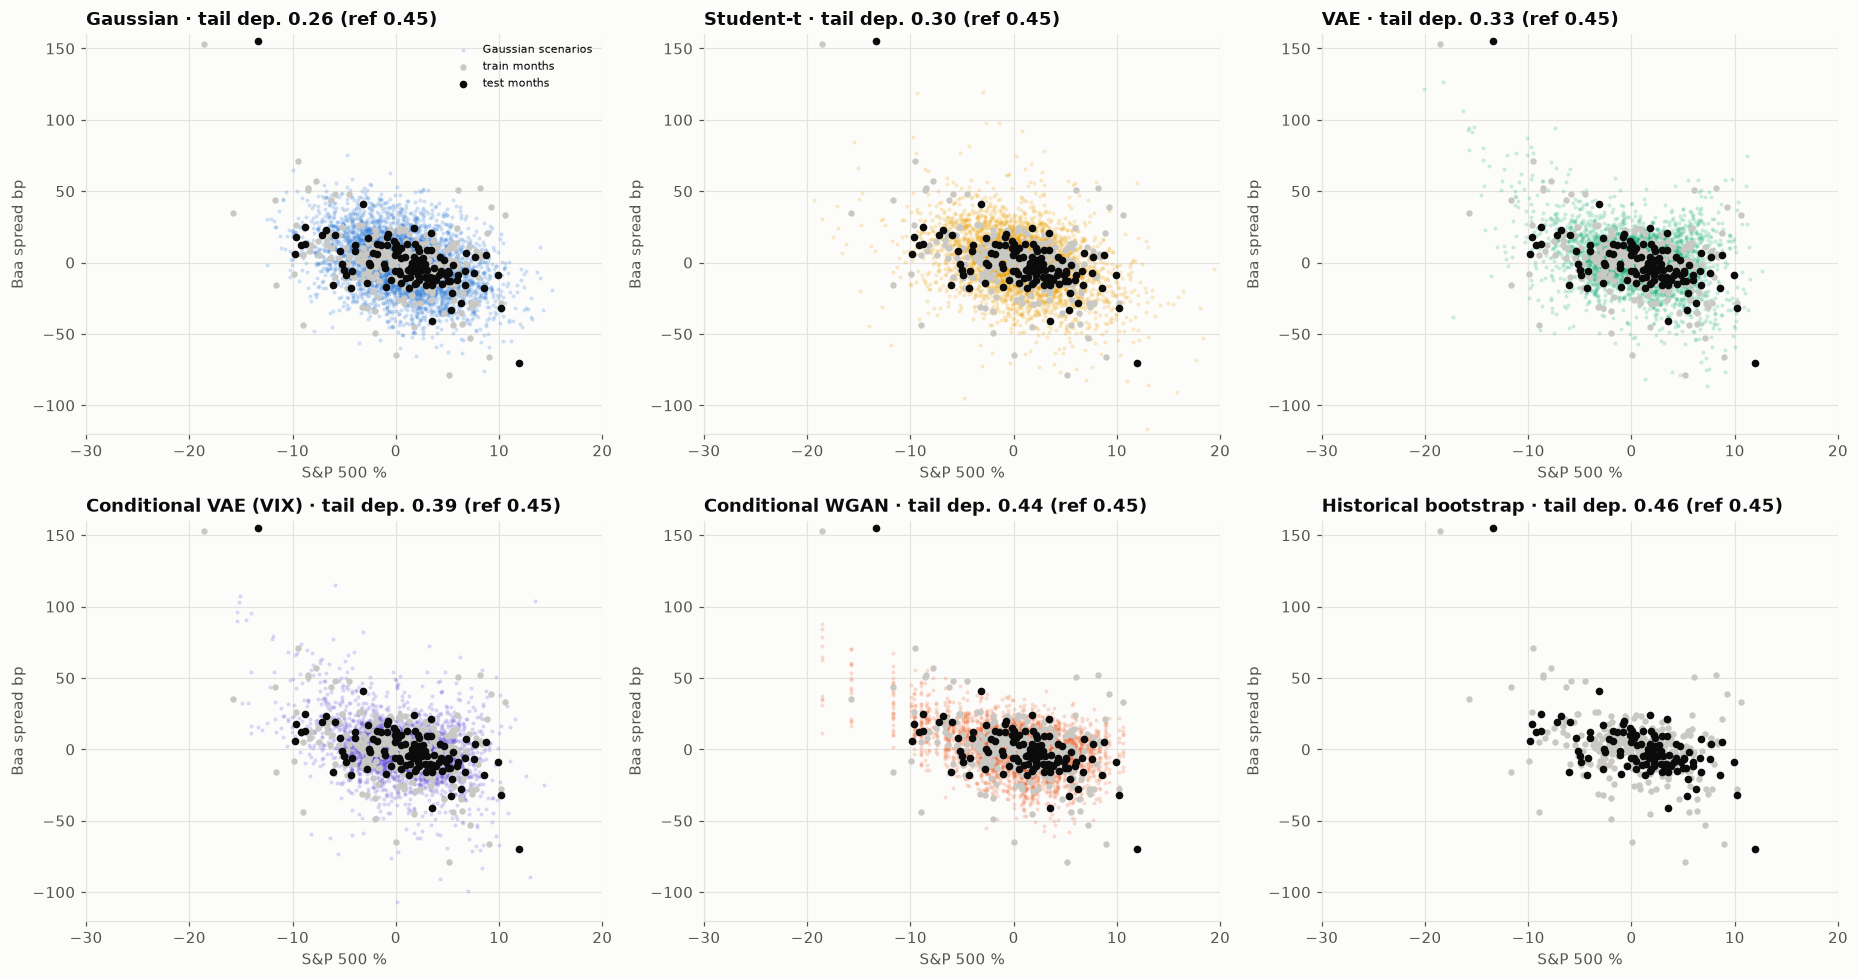

In [11]:
# --- Chart 2: tails and stress dependence, generated vs realised
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
show = [
    "Gaussian",
    "Student-t",
    "VAE",
    "Conditional VAE (VIX)",
    "Conditional WGAN",
    "Historical bootstrap",
]
test_df = X[test]
for ax, name in zip(axes.ravel(), show):
    U = pd.DataFrame(to_units(scen[name][:4_000]), columns=FACTORS)
    ax.scatter(
        U["S&P 500 %"],
        U["Baa spread bp"],
        s=3,
        alpha=0.15,
        color=GEN_COLORS[name],
        label=f"{name} scenarios",
    )
    ax.scatter(
        X.loc[train, "S&P 500 %"],
        X.loc[train, "Baa spread bp"],
        s=10,
        color="#c9c8c3",
        label="train months",
    )
    ax.scatter(
        test_df["S&P 500 %"],
        test_df["Baa spread bp"],
        s=16,
        color=INK,
        label="test months",
    )
    ax.set_xlim(-30, 20)
    ax.set_ylim(-120, 160)
    ax.set_title(
        f"{name} · tail dep."
        f" {scorecard.loc[name, 'tail dependence eq↓/credit↑']:.2f} (ref"
        f" {TD_REF:.2f})"
    )
    ax.set_xlabel("S&P 500 %")
    ax.set_ylabel("Baa spread bp")
axes[0, 0].legend(fontsize=7, loc="upper right")
plt.tight_layout()
save_fig(fig, "02_equity_credit_scenarios")
plt.show()

## 6. Reverse stress: "equities fall 15% in a month, what else happens?"

The conditional WGAN generates the other seven factors given the equity move. The same is done with the linear-Gaussian model (which implies every factor responds proportionally) and with nearest historical analogues. Two real months give a sanity check: **October 2008** (S&P −18%) and **March 2020** (−13%).

In [12]:
def stress_draws(eq_pct, n=N_SCEN):
    c = (eq_pct * 100 - mu_tr["S&P 500 %"]) / sd_tr["S&P 500 %"]
    z_gan = gen_cwgan_given(np.full(n, c))
    z_lin = np.empty((n, D))
    z_lin[:, EQ], z_lin[:, OTHERS] = c, rng.multivariate_normal(
        beta * c, S_cond, n
    )
    # full history here: real analogues
    near = np.argsort(np.abs(Z[:, EQ] - c))[:15]
    z_hist = Z[near][rng.integers(0, len(near), n)]
    return {
        "Conditional WGAN": to_units(z_gan),
        "Linear-Gaussian": to_units(z_lin),
        "Historical analogues (15 nearest)": to_units(z_hist),
    }


stress = {lvl: stress_draws(lvl) for lvl in STRESS_LEVELS}
rows = []
for lvl, d in stress.items():
    for model, U in d.items():
        p = U @ w_pnl
        rows.append({
            "equity shock": f"{lvl:.0%}",
            "model": model,
            **{
                f"median {f}": np.median(U[:, j])
                for j, f in enumerate(FACTORS)
                if j != EQ
            },
            "P&L median $mm": np.median(p),
            "P&L 5% tail $mm": np.quantile(p, 0.05),
        })
stress_table = pd.DataFrame(rows).set_index(["equity shock", "model"])
episodes = X.loc[[pd.Timestamp("2008-10-31"), pd.Timestamp("2020-03-31")]]
episodes = episodes.assign(**{"P&L $mm": episodes.to_numpy() @ w_pnl})
display(episodes.round(1))
stress_table.round(1)

,S&P 500 %,Russell 2000 %,VIX pts,2y yield bp,10y yield bp,Baa spread bp,Dollar %,WTI %,P&L $mm
date,,,,,,,,,
2008-10-31,-18.60,-23.50,20.50,-44.00,16.00,153.00,7.50,-39.10,-144.90
2020-03-31,-13.40,-24.70,13.40,-63.00,-43.00,155.00,0.90,-78.20,-101.10


median Russell 2000 %  \
equity shock model                                                      
-8%          Conditional WGAN                                   -9.20   
             Linear-Gaussian                                    -8.60   
             Historical analogues (15 nearest)                 -10.50   
-15%         Conditional WGAN                                  -18.70   
             Linear-Gaussian                                   -16.10   
             Historical analogues (15 nearest)                 -10.50   
-20%         Conditional WGAN                                  -25.90   
             Linear-Gaussian                                   -21.60   
             Historical analogues (15 nearest)                 -10.50   

                                                median VIX pts  \
equity shock model                                               
-8%          Conditional WGAN                             5.30   
             Linear-Gaussian                              6.10   
             Historical analogues (15 nearest)            6.10   
-15%         Conditional WGAN                            13.70   
             Linear-Gaussian                             11.10   
             Historical analogues (15 nearest)            7.40   
-20%         Conditional WGAN                            21.00   
             Linear-Gaussian                             14.70   
             Historical analogues (15 nearest)            7.40   

                                                median 2y yield bp  \
equity shock model                                                   
-8%          Conditional WGAN                               -26.80   
             Linear-Gaussian                                 -9.70   
             Historical analogues (15 nearest)              -23.00   
-15%         Conditional WGAN                               -74.90   
             Linear-Gaussian                                -16.10   
             Historical analogues (15 nearest)              -21.00   
-20%         Conditional WGAN                              -118.10   
             Linear-Gaussian                                -20.30   
             Historical analogues (15 nearest)              -21.00   

                                                median 10y yield bp  \
equity shock model                                                    
-8%          Conditional WGAN                                -21.40   
             Linear-Gaussian                                  -6.90   
             Historical analogues (15 nearest)               -25.00   
-15%         Conditional WGAN                                -63.50   
             Linear-Gaussian                                 -11.30   
             Historical analogues (15 nearest)                 2.00   
-20%         Conditional WGAN                               -101.50   
             Linear-Gaussian                                 -13.90   
             Historical analogues (15 nearest)                 2.00   

                                                median Baa spread bp  \
equity shock model                                                     
-8%          Conditional WGAN                                  16.20   
             Linear-Gaussian                                   15.90   
             Historical analogues (15 nearest)                 15.00   
-15%         Conditional WGAN                                  43.00   
             Linear-Gaussian                                   28.80   
             Historical analogues (15 nearest)                 18.00   
-20%         Conditional WGAN                                  66.50   
             Linear-Gaussian                                   38.00   
             Historical analogues (15 nearest)                 18.00   

                                                median Dollar %  median WTI %  \
equity shock model                                                              
-8%      

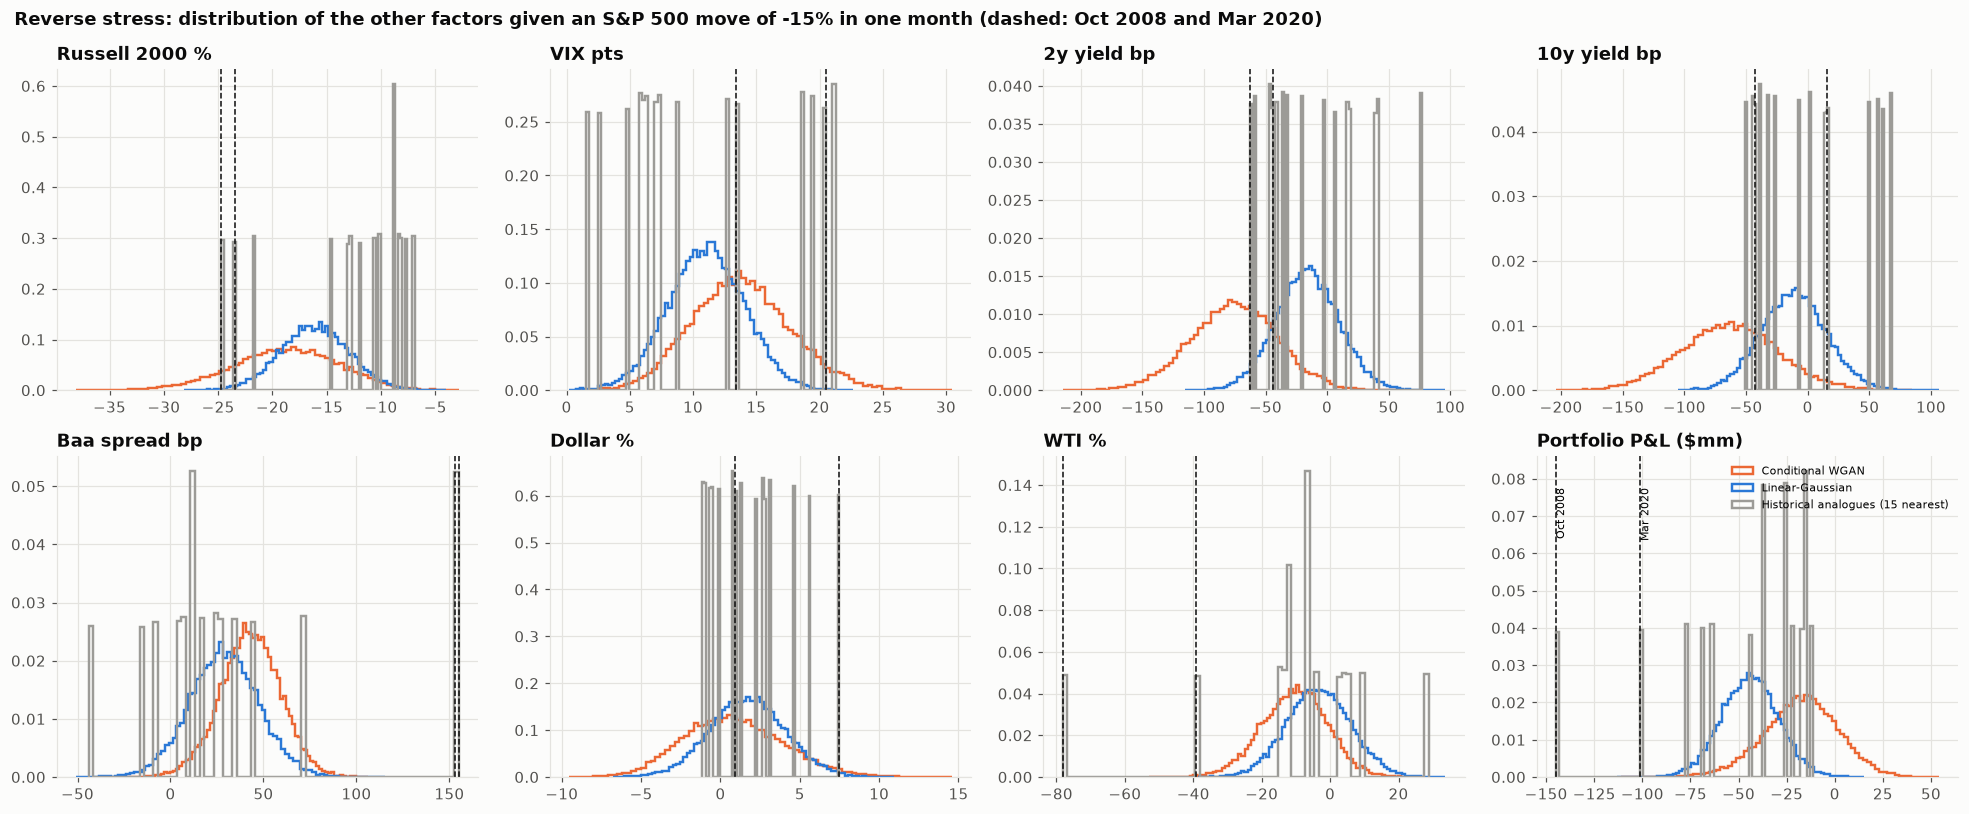

In [13]:
# --- Chart 3: the −15% stress, factor by factor
lvl = -0.15
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
model_cols = {
    "Conditional WGAN": PALETTE[1],
    "Linear-Gaussian": PALETTE[0],
    "Historical analogues (15 nearest)": "#9c9b97",
}
for ax, j in zip(axes.ravel(), OTHERS + [None]):
    if j is None:
        for m, col in model_cols.items():
            p = stress[lvl][m] @ w_pnl
            ax.hist(
                p,
                bins=80,
                histtype="step",
                density=True,
                color=col,
                lw=1.6,
                label=m,
            )
        for d, row in episodes.iterrows():
            ax.axvline(row["P&L $mm"], color=INK, ls="--", lw=1)
            ax.text(
                row["P&L $mm"],
                ax.get_ylim()[1] * 0.9,
                f"{d:%b %Y}",
                fontsize=7,
                rotation=90,
                va="top",
            )
        ax.set_title("Portfolio P&L ($mm)")
        ax.legend(fontsize=7)
        continue
    for m, col in model_cols.items():
        ax.hist(
            stress[lvl][m][:, j],
            bins=80,
            histtype="step",
            density=True,
            color=col,
            lw=1.6,
        )
    for d, row in episodes.iterrows():
        ax.axvline(row[FACTORS[j]], color=INK, ls="--", lw=1)
    ax.set_title(FACTORS[j])
fig.suptitle(
    "Reverse stress: distribution of the other factors given an S&P 500 move"
    f" of {lvl:.0%} in one month (dashed: Oct 2008 and Mar 2020)",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=INK,
)
plt.tight_layout()
save_fig(fig, "03_reverse_stress_15pct")
plt.show()

## 7. The Fed's 2026 severely adverse scenario

The Federal Reserve publishes its supervisory scenarios as quarterly paths. The 2026 **severely adverse** scenario specifies, among others, the Dow Jones Total Stock Market index, the VIX, the 3-month, 5-year and 10-year Treasury rates and the BBB corporate yield, starting from the actual values of 2025 Q4. It says nothing about small caps or oil, and the dollar only through bilateral exchange rates.

The scenario is mapped to this notebook's factors as follows: equities = log change of the Dow Jones Total Market; VIX = change in level; 2-year yield ≈ average change of the 3-month and 5-year rates; 10-year = change in the 10-year yield; credit spread = change in (BBB yield − 10-year yield); dollar = minus the log change of USD/EUR (the euro is 58% of the dollar index).

Two horizons are used: the **first quarter** (2026 Q1, the sharpest move) and the **peak-to-trough** move to the equity low (2026 Q3).

The generators are then run on the same equity path: each month gets one third (or one ninth) of the Fed's equity move, the other factors are drawn conditionally and summed. This answers a validator's question directly: given the Fed's equity shock, does the model produce the Fed's credit, rates and volatility moves, and what does the generator add for the factors the Fed does not specify?

In [14]:
FED_BASE = "https://www.federalreserve.gov/supervisionreg/files/"
FED_FILES = [
    "2026_Final_Historic_Domestic.csv",
    "2026_Final_Supervisory_Severely_Adverse_Domestic.csv",
    "2026_Final_Historic_International.csv",
    "2026_Final_Supervisory_Severely_Adverse_International.csv",
]


def fetch_fed():
    parts = []
    for f in FED_FILES:
        d = pd.read_csv(
            io.StringIO(
                requests.get(
                    FED_BASE + f, headers=BROWSER_HEADERS, timeout=30
                ).text
            )
        )
        parts.append(d.assign(file=f).astype(str))
    return pd.concat(parts, ignore_index=True)


fed_raw = cached("fed_2026_scenarios", fetch_fed, max_age_hours=24 * 30)
dom = fed_raw[fed_raw["file"].str.contains("Domestic")].set_index(
    ["Scenario Name", "Date"]
)
intl = fed_raw[fed_raw["file"].str.contains("International")].set_index(
    ["Scenario Name", "Date"]
)
num = lambda df, col: pd.to_numeric(df[col], errors="coerce")
base_q = dom.loc["Actual"].index[-1]
sa_q = list(dom.loc["Supervisory Severely Adverse"].index)


def fed_row(scen, q):
    d, i = dom.loc[(scen, q)], intl.loc[(scen, q)]
    f = lambda c: float(pd.to_numeric(d[c]))
    return {
        "eq": f("Dow Jones Total Stock Market Index (Level)"),
        "vix": f("Market Volatility Index (Level)"),
        "y2": (f("3-month Treasury rate") + f("5-year Treasury yield")) / 2,
        "y10": f("10-year Treasury yield"),
        "spread": f("BBB corporate yield") - f("10-year Treasury yield"),
        "eurusd": float(
            pd.to_numeric(
                i["Euro area bilateral dollar exchange rate (USD/euro)"]
            )
        ),
    }


def fed_move(q):
    b, x = fed_row("Actual", base_q), fed_row(
        "Supervisory Severely Adverse", q
    )
    return {
        "S&P 500 %": np.log(x["eq"] / b["eq"]) * 100,
        "VIX pts": x["vix"] - b["vix"],
        "2y yield bp": (x["y2"] - b["y2"]) * 100,
        "10y yield bp": (x["y10"] - b["y10"]) * 100,
        "Baa spread bp": (x["spread"] - b["spread"]) * 100,
        "Dollar %": -np.log(x["eurusd"] / b["eurusd"]) * 100,
    }


eq_path = {q: fed_row("Supervisory Severely Adverse", q)["eq"] for q in sa_q}
trough_q = min(eq_path, key=eq_path.get)
HORIZONS = {
    f"First quarter ({sa_q[0]})": (sa_q[0], 3),
    f"Peak to trough ({base_q} → {trough_q})": (
        trough_q,
        3 * (sa_q.index(trough_q) + 1),
    ),
}


def path_draws(eq_total_pct, months, n=10_000):
    """
    Sum of `months` monthly draws, each conditioned on an equal share of the
    total equity log move.
    """
    c = (eq_total_pct / months - mu_tr["S&P 500 %"]) / sd_tr["S&P 500 %"]
    gan = sum(to_units(gen_cwgan_given(np.full(n, c))) for _ in range(months))
    lin = np.zeros((n, D))
    for _ in range(months):
        z = np.empty((n, D))
        z[:, EQ], z[:, OTHERS] = c, rng.multivariate_normal(
            beta * c, S_cond, n
        )
        lin += to_units(z)
    return {"Conditional WGAN": gan, "Linear-Gaussian": lin}


fed_rows, fed_pnl = [], {}
for label, (q, months) in HORIZONS.items():
    mv = fed_move(q)
    draws = path_draws(mv["S&P 500 %"], months)
    for j, f in enumerate(FACTORS):
        row = {
            "horizon": label,
            "factor": f,
            "Fed scenario": mv.get(f, np.nan),
        }
        for m, U in draws.items():
            row[f"{m} median"] = np.median(U[:, j])
            row[f"{m} 5–95%"] = (
                f"{np.percentile(U[:, j], 5):.0f} to"
                f" {np.percentile(U[:, j], 95):.0f}"
            )
        fed_rows.append(row)
    # Portfolio P&L: Fed-specified factors fixed; the WGAN fills in the factors
    # the Fed does not specify (Russell 2000, WTI)
    U = draws["Conditional WGAN"].copy()
    for j, f in enumerate(FACTORS):
        if f in mv:
            U[:, j] = mv[f]
    fed_pnl[label] = {
        "Fed-specified + WGAN for the rest": U @ w_pnl,
        "WGAN for every factor": draws["Conditional WGAN"] @ w_pnl,
        "Linear-Gaussian for every factor": draws["Linear-Gaussian"] @ w_pnl,
    }
fed_table = pd.DataFrame(fed_rows).set_index(["horizon", "factor"])
fed_pnl_table = pd.DataFrame(
    {h: {k: np.median(v) for k, v in d.items()} for h, d in fed_pnl.items()}
).T
print(
    f"Fed 2026 severely adverse: base {base_q}, equity trough {trough_q} "
    f"({fed_move(trough_q)['S&P 500 %']:.0f}% log change); P&L medians in $mm:"
)
display(fed_pnl_table.round(0))
fed_table.round(1)

Fed 2026 severely adverse: base 2025 Q4, equity trough 2026 Q3 (-86% log change); P&L medians in $mm:


,Fed-specified + WGAN for the rest,WGAN for every factor,Linear-Gaussian for every factor
First quarter (2026 Q1),-239.00,-53.00,-144.00
Peak to trough (2025 Q4 → 2026 Q3),-334.00,-130.00,-252.00


Fed scenario  \
horizon                            factor                         
First quarter (2026 Q1)            S&P 500 %             -49.00   
                                   Russell 2000 %           NaN   
                                   VIX pts                33.30   
                                   2y yield bp          -125.00   
                                   10y yield bp         -100.00   
                                   Baa spread bp         340.00   
                                   Dollar %                4.40   
                                   WTI %                    NaN   
Peak to trough (2025 Q4 → 2026 Q3) S&P 500 %             -86.30   
                                   Russell 2000 %           NaN   
                                   VIX pts                44.50   
                                   2y yield bp          -295.00   
                                   10y yield bp         -170.00   
                                   Baa spread bp         470.00   
                                   Dollar %               11.80   
                                   WTI %                    NaN   

                                                   Conditional WGAN median  \
horizon                            factor                                    
First quarter (2026 Q1)            S&P 500 %                        -49.00   
                                   Russell 2000 %                   -62.00   
                                   VIX pts                           47.00   
                                   2y yield bp                     -259.10   
                                   10y yield bp                    -219.10   
                                   Baa spread bp                    147.00   
                                   Dollar %                           2.30   
                                   WTI %                            -36.60   
Peak to trough (2025 Q4 → 2026 Q3) S&P 500 %                        -86.30   
                                   Russell 2000 %                  -103.00   
                                   VIX pts                           63.70   
                                   2y yield bp                     -327.20   
                                   10y yield bp                    -266.40   
                                   Baa spread bp                    191.80   
                                   Dollar %                           7.60   
                                   WTI %                            -38.30   

                                                  Conditional WGAN 5–95%  \
horizon                            factor                                  
First quarter (2026 Q1)            S&P 500 %                  -49 to -49   
                                   Russell 2000 %             -77 to -48   
                                   VIX pts                      36 to 59   
                                   2y yield bp              -362 to -158   
                                   10y yield bp             -333 to -103   
                                   Baa spread bp               99 to 193   
                                   Dollar %                     -6 to 12   
                                   WTI %                       -65 to -9   
Peak to trough (2025 Q4 → 2026 Q3) S&P 500 %                  -86 to -86   
                                   Russell 2000 %            -124 to -84   
                                   VIX pts                      48 to 80   
                                   2y yield bp              -477 to -178   
                                   10y yield bp             -429 to -105   
                                   Baa spread bp              117 to 264   
                                   Dollar %                     -6 to 21   
                                   WTI %                        -82 to 2   

                                                   Linear-Gaussian med

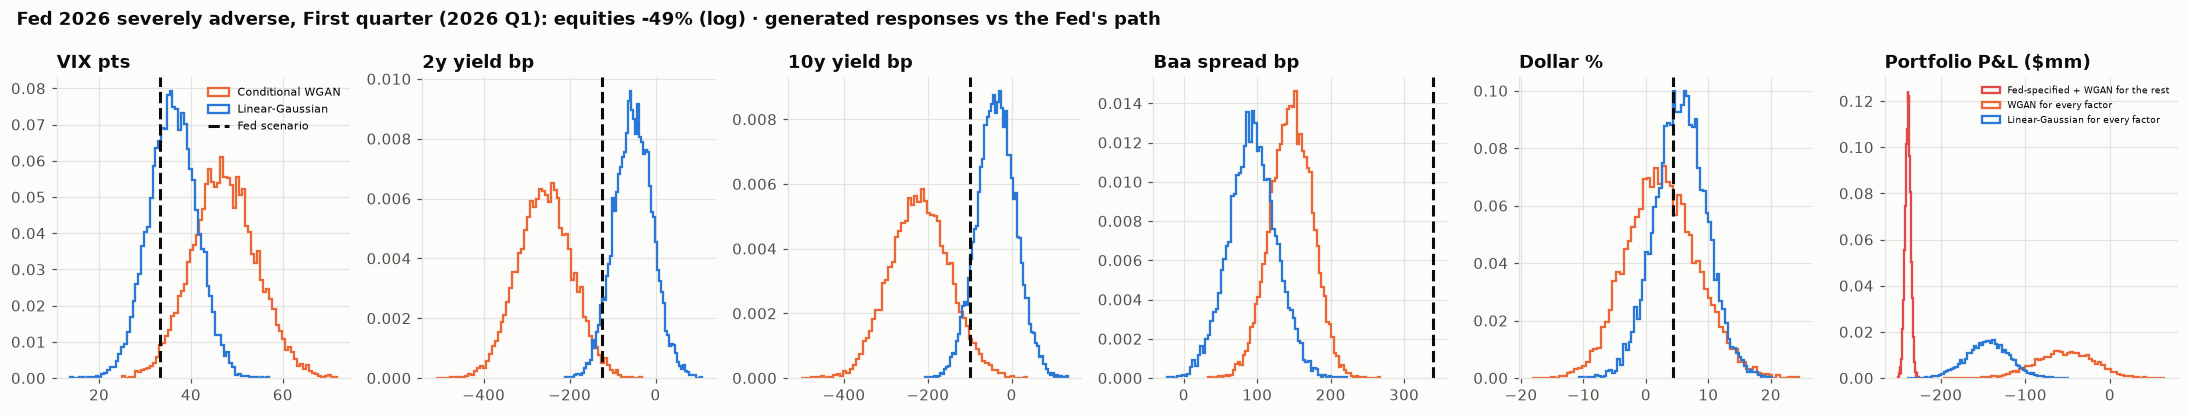

In [15]:
# --- Chart 4: the Fed scenario against the generators
label = list(HORIZONS)[0]
q, months = HORIZONS[label]
mv = fed_move(q)
draws = path_draws(mv["S&P 500 %"], months)
show = ["VIX pts", "2y yield bp", "10y yield bp", "Baa spread bp", "Dollar %"]
fig, axes = plt.subplots(1, len(show) + 1, figsize=(20, 3.8))
for ax, f in zip(axes, show):
    j = FACTORS.index(f)
    for m, col in [
        ("Conditional WGAN", PALETTE[1]),
        ("Linear-Gaussian", PALETTE[0]),
    ]:
        ax.hist(
            draws[m][:, j],
            bins=70,
            histtype="step",
            density=True,
            color=col,
            lw=1.5,
            label=m,
        )
    ax.axvline(mv[f], color=INK, lw=2, ls="--", label="Fed scenario")
    ax.set_title(f)
axes[0].legend(fontsize=7)
ax = axes[-1]
for k, col in zip(fed_pnl[label], [PALETTE[7], PALETTE[1], PALETTE[0]]):
    ax.hist(
        fed_pnl[label][k],
        bins=70,
        histtype="step",
        density=True,
        color=col,
        lw=1.5,
        label=k,
    )
ax.set_title("Portfolio P&L ($mm)")
ax.legend(fontsize=6)
fig.suptitle(
    f"Fed 2026 severely adverse, {label}: equities {mv['S&P 500 %']:.0f}%"
    " (log) · generated responses vs the Fed's path",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=INK,
)
plt.tight_layout()
save_fig(fig, "04_fed_severely_adverse")
plt.show()
fed_table.to_csv(OUT_DIR / "fed_2026_severely_adverse_vs_generators.csv")

## 8. Results dashboard

In [16]:
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.16,
    horizontal_spacing=0.1,
    subplot_titles=(
        "Energy distance to test months (lower is better)",
        "95% VaR exceedances in test months",
        "Conditional energy score, worst-decile equity months",
        "Portfolio P&L under reverse stress, 5% tail ($mm)",
    ),
)
names = list(scorecard.index)
dash.add_trace(
    go.Bar(
        x=names,
        y=scorecard["energy distance"],
        marker_color=[GEN_COLORS[n] for n in names],
        showlegend=False,
        text=scorecard["energy distance"].round(3),
        textposition="outside",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=names,
        y=scorecard["test exceedances"],
        marker_color=[GEN_COLORS[n] for n in names],
        showlegend=False,
        text=scorecard["test exceedances"].astype(int),
        textposition="outside",
    ),
    1,
    2,
)
dash.add_hline(
    y=0.05 * len(pnl_test),
    line_dash="dash",
    line_color=INK_2,
    row=1,
    col=2,
    annotation_text=f"expected {0.05 * len(pnl_test):.1f}",
)
ct = cond_table["mean energy score (worst-decile equity months)"]
dash.add_trace(
    go.Bar(
        x=ct.index,
        y=ct.values,
        showlegend=False,
        text=ct.round(2),
        textposition="outside",
        marker_color=[
            PALETTE[0] if g == "state" else PALETTE[1]
            for g in cond_table["group"]
        ],
    ),
    2,
    1,
)
for m, col in model_cols.items():
    vals = [
        stress_table.loc[(f"{l:.0%}", m), "P&L 5% tail $mm"]
        for l in STRESS_LEVELS
    ]
    dash.add_trace(
        go.Bar(
            x=[f"{l:.0%}" for l in STRESS_LEVELS],
            y=vals,
            name=m,
            marker_color=col,
        ),
        2,
        2,
    )
best = scorecard["energy distance"].idxmin()
dash.update_layout(
    height=950,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    barmode="group",
    legend=dict(orientation="h", y=-0.08),
    margin=dict(t=130),
    title=dict(
        x=0.01,
        text=(
            "<b>Generative stress scenarios · trained 1990–2016, tested"
            f" {X.index[test][0]:%b %Y}–{X.index[-1]:%b %Y}</b><br>"
            f"<span style='font-size:13px;color:{INK_2}'>8 monthly risk"
            " factors · 6 generators · closest to test distribution:"
            f" {best} · "
            "−15% equity month, 5% tail P&L (WGAN):"
            f" ${stress_table.loc[('-15%', 'Conditional WGAN'), 'P&L 5% tail $mm']:,.0f}mm</span>"
        ),
    ),
)
dash.update_xaxes(tickangle=-25)
save_dashboard(dash, "dashboard")
scorecard.to_csv(OUT_DIR / "generator_scorecard.csv")
cond_table.to_csv(OUT_DIR / "conditional_energy_scores.csv")
stress_table.to_csv(OUT_DIR / "reverse_stress_table.csv")
pd.DataFrame(
    to_units(
        gen_cwgan_given(
            np.full(5_000, (-15 - mu_tr["S&P 500 %"]) / sd_tr["S&P 500 %"])
        )
    ),
    columns=FACTORS,
).to_csv(OUT_DIR / "wgan_scenarios_equity_minus15.csv", index=False)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

Trained on 1990–2016 (323 months), tested on January 2017 – September 2026 (117 months):

- **No generator is clearly closest to what happened.** Energy distances to the test distribution are all between 0.05 and 0.07; the Student-t is marginally best and the deep generators are not better than the historical bootstrap. With 323 training months there is not enough data for a neural generator to beat a well-chosen parametric model *on average*.

**The deep generators win where it matters for stress: tail dependence.** The probability that credit spreads are in their top decile when equities are in their bottom decile is 0.45 in the data. The Gaussian gives 0.26 and the Student-t 0.30: both understate how credit and equities crash together.

The conditional WGAN gives 0.44 and the CVAE 0.39, close to the data, and the WGAN also has the smallest error in the stress-period correlation matrix (2.21 vs 2.89 for the Gaussian).

**Every model failed the VaR backtest.** The stylised treasury portfolio breached its 95% one-month VaR 14–18 times in 117 test months, against about 6 expected (Kupiec p ≈ 0 for all). The cause is the 2022 rate shock: this portfolio is long duration, and the training period contains nearly 30 years in which bonds rallied when equities fell.

No generator trained on 1990–2016 could produce a year in which **both** sold off hard. The conditional models, which learned the old regime more precisely, breach most (18). That is the main lesson of the notebook: a generative model reproduces its training history, including its regime.

**Conditional on the equity move, the simple model is best.** Given the month's actual S&P 500 return, the linear-Gaussian conditional predicts the other seven factors better (energy score 1.56 overall, 2.74 in bad months) than the WGAN (1.62 and 2.88) or historical analogues (1.61 and 2.84). The VIX-conditional CVAE barely improves on the unconditional bootstrap (1.88 vs 1.92). The starting VIX carries little information about next month's joint move.

- **Reverse stress shows both the promise and the danger of a nonlinear generator.**
  - At a −8% equity month, all three methods agree: credit +15–16 bp, VIX +5–6 points, Russell 2000 −9 to −11%.
  - At −15% and −20%, the WGAN produces nonlinear responses (Baa spread +43 and +67 bp against +29 and +38 for the linear model, VIX +14 and +21) that look like October 2008 (+153 bp, +20 VIX).
  - It also extrapolates a Treasury rally (2y −75 and −118 bp) far beyond any month in history. That rally hedges the portfolio, so the WGAN's 5% tail P&L barely grows with the shock (−$39mm, −$50mm, −$54mm). The real October 2008 cost −$145mm, and the historical analogues give −$145mm.

**Against the Fed's 2026 severely adverse scenario, the generators understate credit and overstate the Treasury rally.** In the first quarter the Fed takes equities down 49% (log) and widens the BBB–Treasury spread by 340 bp, with the 10-year yield falling 100 bp. Conditioned on the same equity path, the WGAN widens the Baa spread by only 147 bp (5–95%: 99–193) and pushes the 10-year down 219 bp; the linear model gives +94 bp and −37 bp.

For the stylised portfolio, which is long credit and long duration, this matters a lot. The Fed's path, with the WGAN filling in small caps and oil, costs **−$239mm** in the quarter (−$334mm peak to trough), against −$53mm if the WGAN generates every factor and −$144mm for the linear model.

The Fed's scenario is more severe than anything the historical co-movements imply, which is exactly its purpose.

- **Summing monthly draws is a simplification.** Spreading a −49% quarter over three −16% months and adding the conditional draws ignores mean reversion within the quarter, which inflates the generated VIX move (+47 points against the Fed's +33).

**For a stress-testing function,** the generators are useful to *widen* the set of scenarios, especially for tail co-movement, but not as the source of the severe scenario itself. Only 19 months since 1990 had equity falls of 8% or more and only three fell by more than 12%, so beyond −15% every model is extrapolating.

A credible severe scenario still needs a narrative (or the Fed's supervisory paths), with the generator filling in the factors the narrative does not specify, constrained to be at least as bad as history.

**Limitations**

- Monthly data and about 440 observations: too few for a GAN to learn tails reliably. Higher-frequency data (weekly, overlapping windows) would add data, at the cost of serial dependence.
- One stylised portfolio with linear sensitivities; no convexity, no option books.
- Hyper-parameters (latent size, network widths, training steps) were set once. A GAN's output is known to vary across training runs; several seeds would show the spread of its stress responses.
- The Fed scenario is mapped onto monthly factors with simplifications: the 2-year yield is approximated by the 3-month and 5-year rates, the BBB–Treasury spread stands in for the Baa spread, and the dollar index by USD/EUR.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2018). *Stress testing principles*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d450.htm
- Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association, 102*(477), 359–378. https://doi.org/10.1198/016214506000001437
- Longin, F., & Solnik, B. (2001). Extreme correlation of international equity markets. *The Journal of Finance, 56*(2), 649–676. https://doi.org/10.1111/0022-1082.00340
- Székely, G. J., & Rizzo, M. L. (2013). Energy statistics: A class of statistics based on distances. *Journal of Statistical Planning and Inference, 143*(8), 1249–1272. https://doi.org/10.1016/j.jspi.2013.03.018

### Machine learning and deep learning

- Kingma, D. P., & Welling, M. (2014). Auto-encoding variational Bayes. In *Proceedings of the 2nd International Conference on Learning Representations*. https://arxiv.org/abs/1312.6114
- Sohn, K., Lee, H., & Yan, X. (2015). Learning structured output representation using deep conditional generative models. *Advances in Neural Information Processing Systems, 28*. https://proceedings.neurips.cc/paper/2015/hash/8d55a249e6baa5c06772297520da2051-Abstract.html
- Gulrajani, I., Ahmed, F., Arjovsky, M., Dumoulin, V., & Courville, A. (2017). Improved training of Wasserstein GANs. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1704.00028
- Wiese, M., Knobloch, R., Korn, R., & Kretschmer, P. (2020). Quant GANs: Deep generation of financial time series. *Quantitative Finance, 20*(9), 1419–1440. https://doi.org/10.1080/14697688.2020.1730426